In [1]:
!pip install -q transformers torch pillow

In [2]:
from transformers import AutoImageProcessor, SiglipForImageClassification
from PIL import Image
import torch
import matplotlib.pyplot as plt
import os

In [3]:
MODEL_NAME = "prithivMLmods/BrainTumor-Classification-Mini"

model = SiglipForImageClassification.from_pretrained(MODEL_NAME)

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

model.eval()

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

SiglipForImageClassification(
  (vision_model): SiglipVisionModel(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): SiglipMLP(
            (activation_fn): GELUTanh()
            (fc1): Linear(in_features=768, out_features=3072, bi

In [4]:
print("Clases configuradas en el modelo:\n")

for indice, clase in model.config.id2label.items():
    print(f"{indice} -> {clase}")

Clases configuradas en el modelo:

0 -> No Tumor
1 -> Glioma
2 -> Meningioma
3 -> Pituitary


In [6]:
ruta_imagen = "Te-gl_10.jpg"

imagen = Image.open(ruta_imagen).convert("RGB")

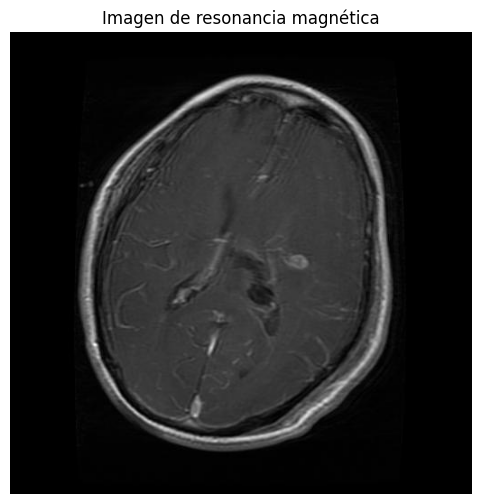

In [7]:
plt.figure(figsize=(6, 6))

plt.imshow(imagen)

plt.title("Imagen de resonancia magnética")
plt.axis("off")

plt.show()

In [8]:
inputs = processor(
    images=imagen,
    return_tensors="pt"
)

print("Imagen preparada para el modelo.")
print("Dimensiones de entrada:", inputs["pixel_values"].shape)

Imagen preparada para el modelo.
Dimensiones de entrada: torch.Size([1, 3, 224, 224])


In [9]:
with torch.no_grad():
    outputs = model(**inputs)

In [10]:
probabilidades = torch.softmax(outputs.logits, dim=1)[0]

print("Probabilidades de cada clase:\n")

for indice, probabilidad in enumerate(probabilidades):
    clase = model.config.id2label[indice]
    porcentaje = probabilidad.item() * 100

    print(f"{clase}: {porcentaje:.2f}%")

Probabilidades de cada clase:

No Tumor: 0.00%
Glioma: 99.99%
Meningioma: 0.00%
Pituitary: 0.00%


In [11]:
indice_prediccion = torch.argmax(probabilidades).item()

clase_predicha = model.config.id2label[indice_prediccion]

confianza = probabilidades[indice_prediccion].item() * 100

In [12]:
descripciones = {
    "No Tumor":
        "El modelo clasifica la imagen como No Tumor, "
        "indicando que la imagen pertenece a la categoría "
        "sin evidencia de tumor dentro de las clases reconocidas por el modelo.",

    "Glioma":
        "El modelo clasifica la imagen como Glioma. "
        "Los gliomas son tumores que se originan en células gliales "
        "del sistema nervioso central.",

    "Meningioma":
        "El modelo clasifica la imagen como Meningioma. "
        "Los meningiomas son tumores que se desarrollan en las "
        "membranas que rodean el cerebro y la médula espinal.",

    "Pituitary":
        "El modelo clasifica la imagen como Pituitary. "
        "Esta categoría corresponde a tumores relacionados con "
        "la región de la glándula hipófisis."
}

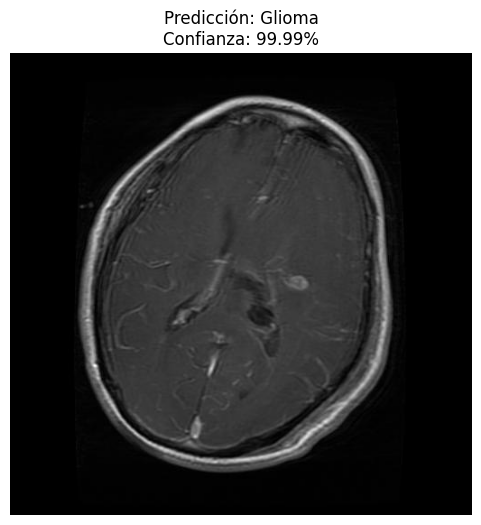

RESULTADO DEL MODELO
Clase: Glioma
Confianza: 99.99%

Descripción:
El modelo clasifica la imagen como Glioma. Los gliomas son tumores que se originan en células gliales del sistema nervioso central.


In [13]:
plt.figure(figsize=(6, 6))

plt.imshow(imagen)

plt.axis("off")

plt.title(
    f"Predicción: {clase_predicha}\n"
    f"Confianza: {confianza:.2f}%"
)

plt.show()

print("RESULTADO DEL MODELO")
print(f"Clase: {clase_predicha}")
print(f"Confianza: {confianza:.2f}%")
print()
print("Descripción:")
print(descripciones[clase_predicha])
